In [1]:
library(tidyverse)

library(grid)
library(gridExtra)
library(patchwork)

source("../evaluation_utils/plots_eda.R")
source("../evaluation_utils/evaluation_funcs.R")

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine




In [2]:
cbPalette <- c("#CC79A7", "#56B4E9", "#009E73", "#F0E442", "#0072B2", "#D55E00")
condition_palette <- c("#44abe7", "#c55702", "#009E73", "#F0E442")

# Load data

In [ ]:
data_path <- "../evaluation_data/quartet_multiomics/"
modalities <- c("Transcriptomics", "Proteomics", "Metabolomics")
donor_levels <- c("D5", "D6", "F7", "M8")

read_feature_matrix <- function(path) {
    read.csv(path, sep = "	", header = TRUE, row.names = 1, check.names = FALSE)
}

load_modality_data <- function(modality) {
    metadata <- read.csv(
        paste0(data_path, "before/", modality, "/metadata.tsv"),
        sep = "	", header = TRUE, check.names = FALSE
    ) %>%
        mutate(
            condition = factor(condition, levels = donor_levels),
            lab = factor(lab),
            batch_code = factor(batch_code),
            platform = factor(platform),
            rep = factor(rep)
        )
    rownames(metadata) <- metadata$file

    central_uncorrected <- read_feature_matrix(
        paste0(data_path, "before/", modality, "/central_intensities_log_UNION.tsv")
    )
    central_corrected <- read_feature_matrix(
        paste0(data_path, "after/label_aware/", modality, "/intensities_log_Rcorrected_UNION.tsv")
    )

    fed_path <- paste0(data_path, "after/label_aware/", modality, "/FedApp_corrected_data.tsv")
    fed_corrected <- if (file.exists(fed_path)) read_feature_matrix(fed_path) else NULL

    shared_features <- intersect(rownames(central_uncorrected), rownames(central_corrected))
    central_uncorrected <- central_uncorrected[shared_features, rownames(metadata), drop = FALSE]
    central_corrected <- central_corrected[shared_features, rownames(metadata), drop = FALSE]

    if (!is.null(fed_corrected)) {
        fed_corrected <- fed_corrected[shared_features, rownames(metadata), drop = FALSE]
    }

    list(
        central_uncorrected = central_uncorrected,
        central_corrected = central_corrected,
        fed_corrected = fed_corrected,
        metadata = metadata
    )
}

load_combined_data <- function() {
    metadata <- read.csv(
        paste0(data_path, "all_modalities_metadata.tsv"),
        sep = "	", header = TRUE, check.names = FALSE
    ) %>%
        mutate(
            file = pseudo_sample,
            lab = client,
            condition = factor(condition, levels = donor_levels),
            lab = factor(lab)
        )
    rownames(metadata) <- metadata$file

    central_uncorrected <- read_feature_matrix(paste0(data_path, "before/all_modalities_before_kmeans_matrix.tsv"))
    central_corrected <- read_feature_matrix(paste0(data_path, "after/label_aware/all_modalities_corrected_kmeans_matrix.tsv"))
    fed_path <- paste0(data_path, "after/label_aware/all_modalities_fedapp_kmeans_matrix.tsv")
    fed_corrected <- if (file.exists(fed_path)) read_feature_matrix(fed_path) else NULL

    central_uncorrected <- central_uncorrected[, rownames(metadata), drop = FALSE]
    central_corrected <- central_corrected[rownames(central_uncorrected), rownames(metadata), drop = FALSE]

    if (!is.null(fed_corrected)) {
        fed_corrected <- fed_corrected[rownames(central_uncorrected), rownames(metadata), drop = FALSE]
    }

    list(
        central_uncorrected = central_uncorrected,
        central_corrected = central_corrected,
        fed_corrected = fed_corrected,
        metadata = metadata
    )
}

multiomics_data <- setNames(lapply(modalities, load_modality_data), modalities)
combined <- load_combined_data()

dataset_summary <- bind_rows(
    lapply(names(multiomics_data), function(modality) {
        data <- multiomics_data[[modality]]
        tibble(
            dataset = modality,
            features = nrow(data$central_uncorrected),
            samples = ncol(data$central_uncorrected),
            batches = n_distinct(data$metadata$lab),
            donors = n_distinct(data$metadata$condition),
            fedrbe_available = !is.null(data$fed_corrected)
        )
    }),
    tibble(
        dataset = "All modalities",
        features = nrow(combined$central_uncorrected),
        samples = ncol(combined$central_uncorrected),
        batches = n_distinct(combined$metadata$lab),
        donors = n_distinct(combined$metadata$condition),
        fedrbe_available = !is.null(combined$fed_corrected)
    )

)
dataset_summary

# Checks

## Diagnostic plots

In [4]:
# Same diagnostic panels as 03_central_RBE.ipynb, after central correction.
for (modality in modalities) {
    data <- multiomics_data[[modality]]
    plot_diagnostics(data$central_corrected, data$metadata, modality, "after",
                     paste0(data_path, "plots"))
}

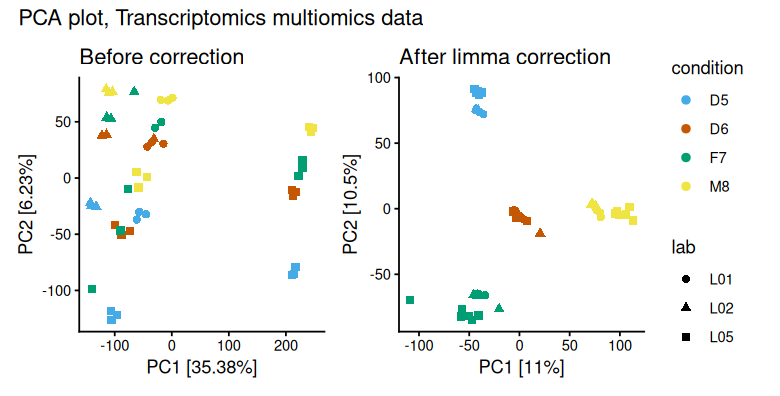

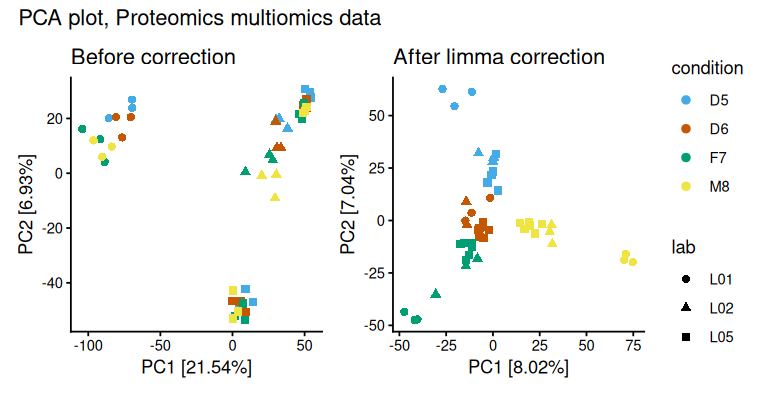

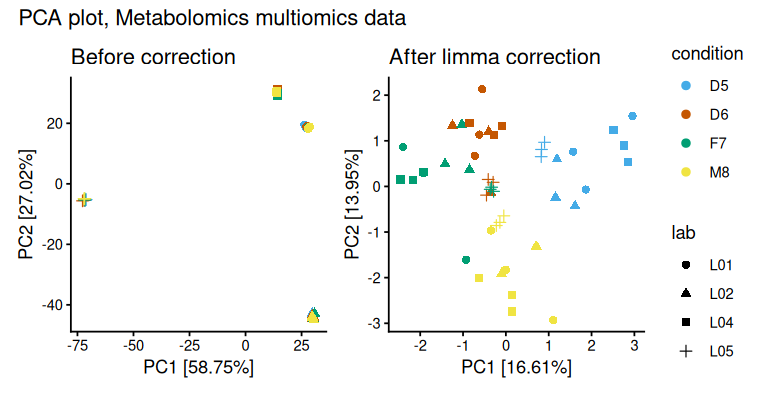

In [5]:
for (modality in modalities) {
    data <- multiomics_data[[modality]]

    pca_plot_uncorrected <- pca_plot(data$central_uncorrected, data$metadata,
        title = "Before correction",
        quantitative_col_name = "file", col_col = "condition", shape_col = "lab",
        show_legend = FALSE, cbPalette = condition_palette)
    pca_plot_corrected <- pca_plot(data$central_corrected, data$metadata,
        title = "After limma correction",
        quantitative_col_name = "file", col_col = "condition", shape_col = "lab",
        show_legend = TRUE, cbPalette = condition_palette)

    layout <- (pca_plot_uncorrected + pca_plot_corrected)
    layout <- layout + plot_annotation(paste("PCA plot,", modality, "multiomics data"))
    options(repr.plot.width = 6.5, repr.plot.height = 3.3)
    print(layout)
}

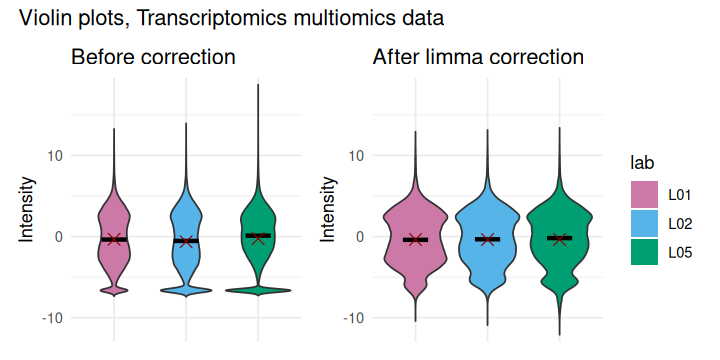

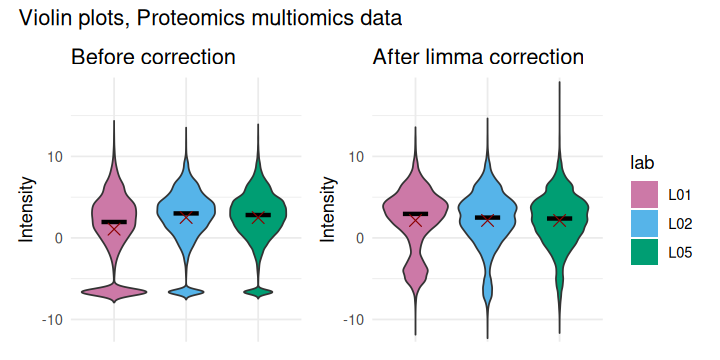

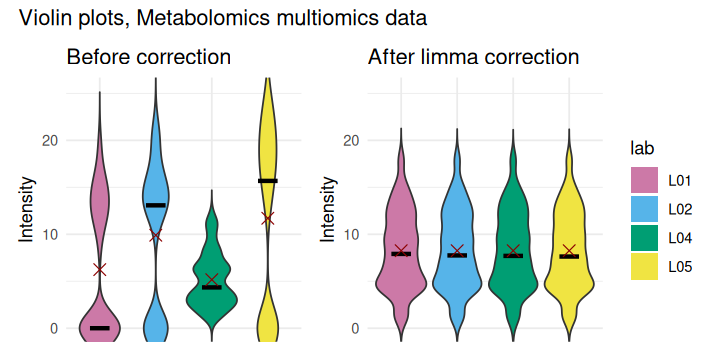

In [6]:
for (modality in modalities) {
    data <- multiomics_data[[modality]]

    y_min <- min(data$central_uncorrected, data$central_corrected, na.rm = TRUE)
    y_max <- max(data$central_uncorrected, data$central_corrected, na.rm = TRUE)
    y_limits <- c(y_min, y_max)

    boxplots_uncorrected <- boxplot_plot_groupped(data$central_uncorrected, data$metadata,
        title = "Before correction",
        quantitativeColumnName = "file",
        color_col = "lab", remove_xnames = TRUE, show_legend = FALSE,
        y_limits = y_limits, cbPalette = cbPalette)
    boxplots_corrected <- boxplot_plot_groupped(data$central_corrected, data$metadata,
        title = "After limma correction",
        quantitativeColumnName = "file",
        color_col = "lab", remove_xnames = TRUE,
        y_limits = y_limits, cbPalette = cbPalette)

    layout <- (boxplots_uncorrected + boxplots_corrected)
    layout <- layout + plot_annotation(paste("Violin plots,", modality, "multiomics data"))
    options(repr.plot.width = 6, repr.plot.height = 3)
    print(layout)
}

### Combined all-modality plots

The combined matrix is the equal-weight, row-z-scored matrix prepared for all-three-modality k-means.

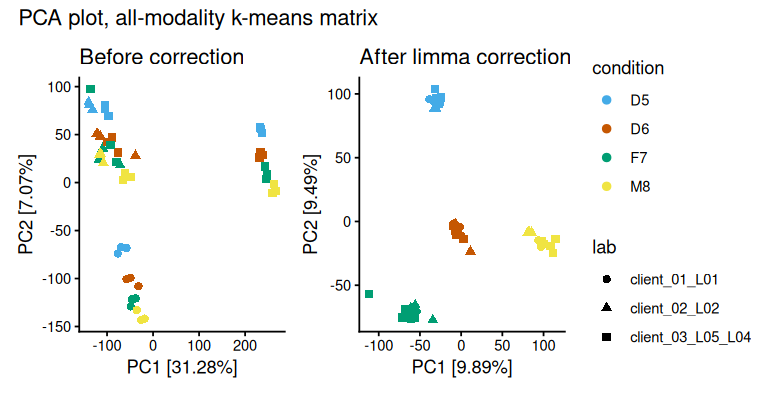

In [7]:
pca_plot_uncorrected <- pca_plot(combined$central_uncorrected, combined$metadata,
    title = "Before correction",
    quantitative_col_name = "file", col_col = "condition", shape_col = "lab",
    show_legend = FALSE, cbPalette = condition_palette)
pca_plot_corrected <- pca_plot(combined$central_corrected, combined$metadata,
    title = "After limma correction",
    quantitative_col_name = "file", col_col = "condition", shape_col = "lab",
    show_legend = TRUE, cbPalette = condition_palette)

layout <- (pca_plot_uncorrected + pca_plot_corrected)
layout <- layout + plot_annotation("PCA plot, all-modality k-means matrix")
options(repr.plot.width = 6.5, repr.plot.height = 3.3)
layout

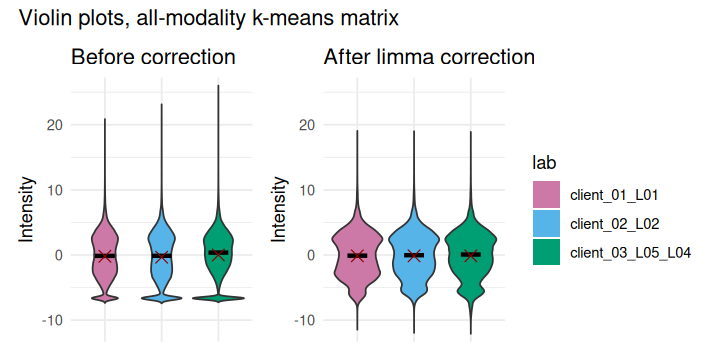

In [8]:
y_min <- min(combined$central_uncorrected, combined$central_corrected, na.rm = TRUE)
y_max <- max(combined$central_uncorrected, combined$central_corrected, na.rm = TRUE)
y_limits <- c(y_min, y_max)

boxplots_uncorrected <- boxplot_plot_groupped(combined$central_uncorrected, combined$metadata,
    title = "Before correction",
    quantitativeColumnName = "file",
    color_col = "lab", remove_xnames = TRUE, show_legend = FALSE,
    y_limits = y_limits, cbPalette = cbPalette)
boxplots_corrected <- boxplot_plot_groupped(combined$central_corrected, combined$metadata,
    title = "After limma correction",
    quantitativeColumnName = "file",
    color_col = "lab", remove_xnames = TRUE,
    y_limits = y_limits, cbPalette = cbPalette)

layout <- (boxplots_uncorrected + boxplots_corrected)
layout <- layout + plot_annotation("Violin plots, all-modality k-means matrix")
options(repr.plot.width = 6, repr.plot.height = 3)
layout

## Linear model per variable

Following batch effect correction, the percentage of variance explained by the condition should be greater than the batch.

In [9]:
library(variancePartition)

Loading required package: limma

Loading required package: BiocParallel


Attaching package: ‘variancePartition’


The following objects are masked from ‘package:limma’:

    eBayes, topTable




In [10]:
form <- ~ condition + lab

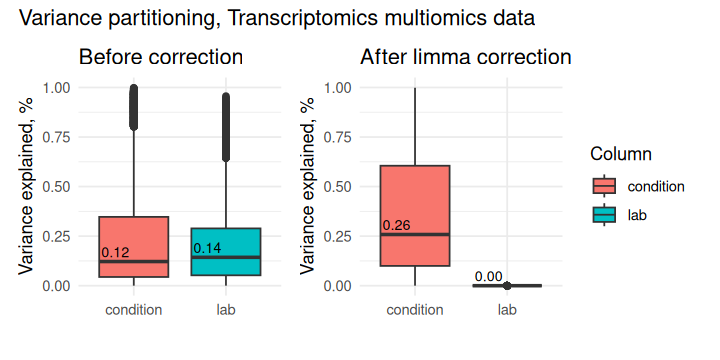

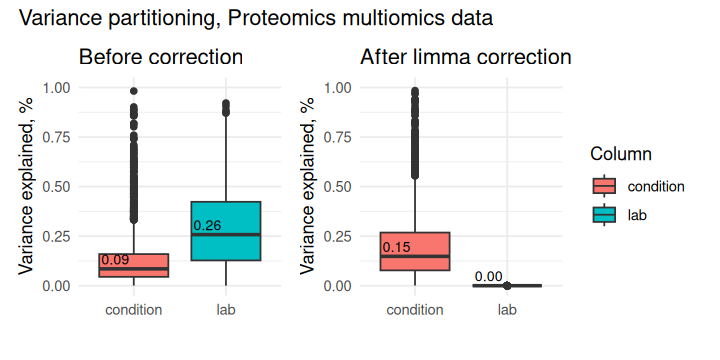

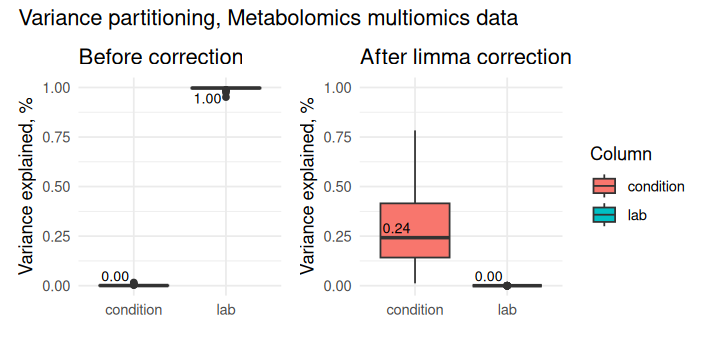

In [11]:
for (modality in modalities) {
    data <- multiomics_data[[modality]]

    lmpv_plot_corrected <- lmpv_plot(data$central_corrected, data$metadata,
        title = "After limma correction", form = form)
    lmpv_plot_uncorrected <- lmpv_plot(data$central_uncorrected, data$metadata,
        title = "Before correction", show_legend = FALSE, form = form)

    layout <- (lmpv_plot_uncorrected + lmpv_plot_corrected)
    layout <- layout + plot_annotation(paste("Variance partitioning,", modality, "multiomics data"))
    options(repr.plot.width = 6, repr.plot.height = 3)
    print(layout)
}

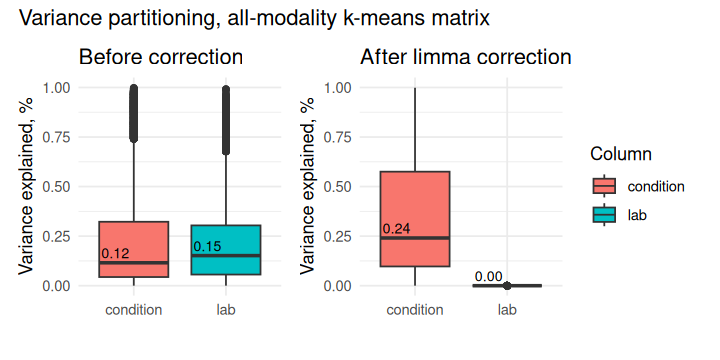

In [12]:
lmpv_plot_corrected <- lmpv_plot(combined$central_corrected, combined$metadata,
    title = "After limma correction", form = form)
lmpv_plot_uncorrected <- lmpv_plot(combined$central_uncorrected, combined$metadata,
    title = "Before correction", show_legend = FALSE, form = form)

layout <- (lmpv_plot_uncorrected + lmpv_plot_corrected)
layout <- layout + plot_annotation("Variance partitioning, all-modality k-means matrix")
options(repr.plot.width = 6, repr.plot.height = 3)
layout

## FedRBE / FC app plots

If the FeatureCloud app outputs are present (`FedApp_corrected_data.tsv` and `prepared/corrected_fedrbe_matrix.tsv`), generate the same before-vs-FedRBE diagnostics using the shared plotting helpers.

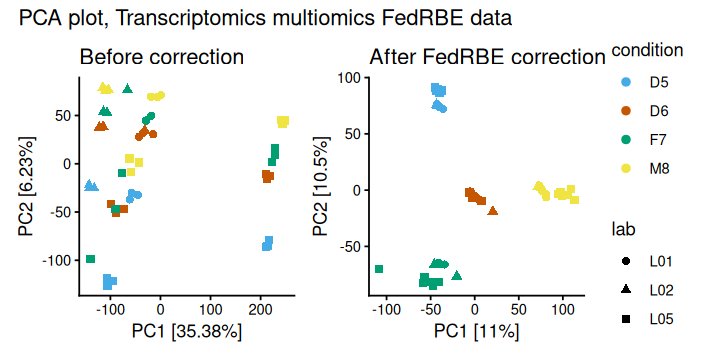

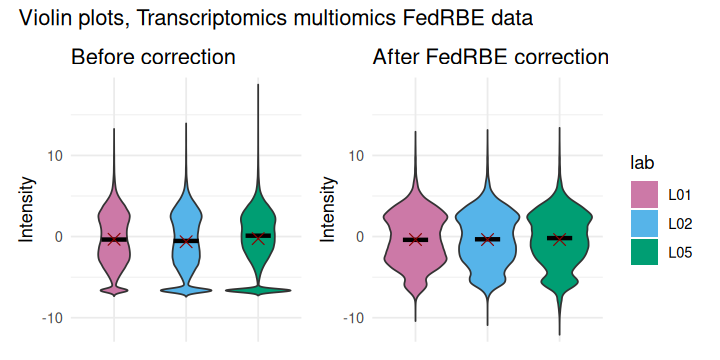

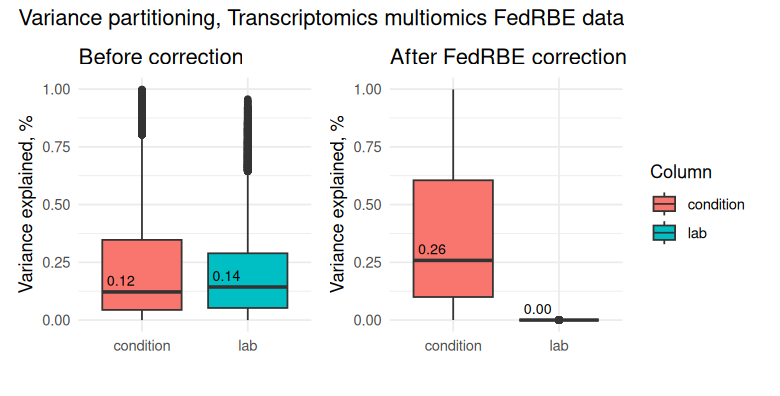

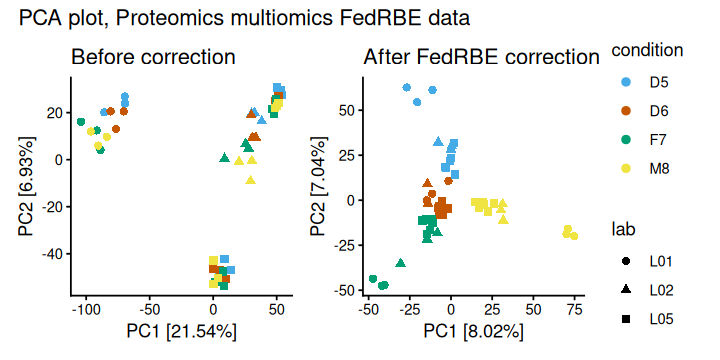

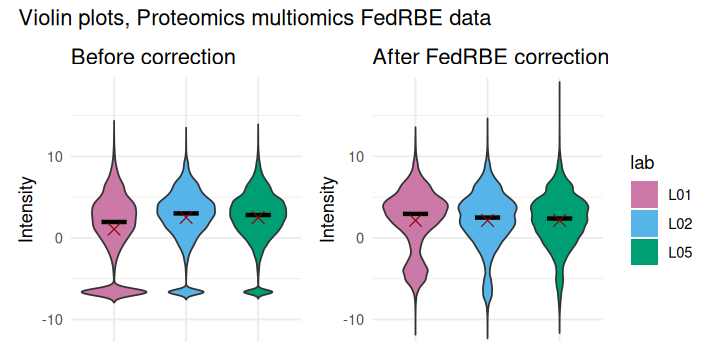

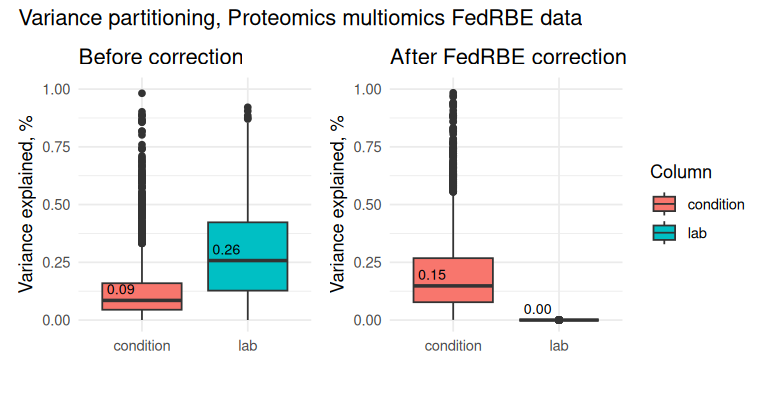

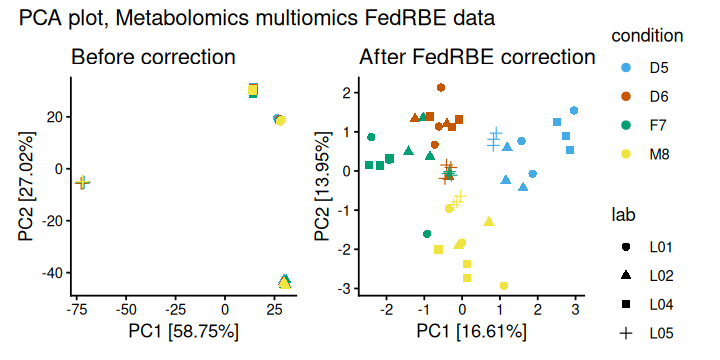

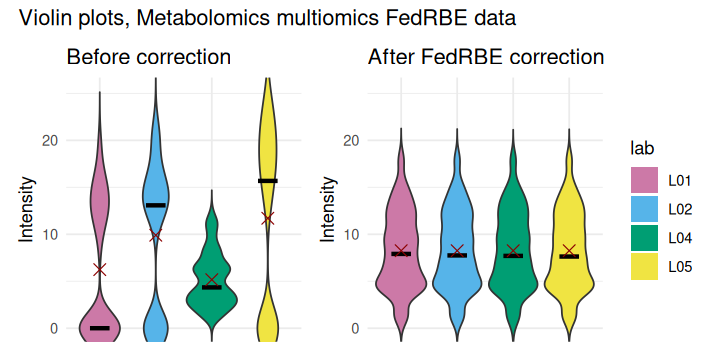

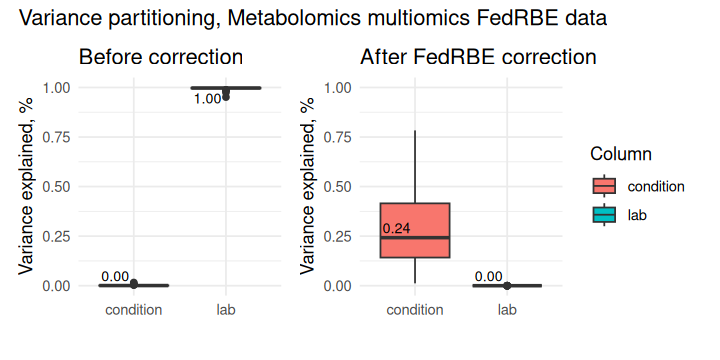

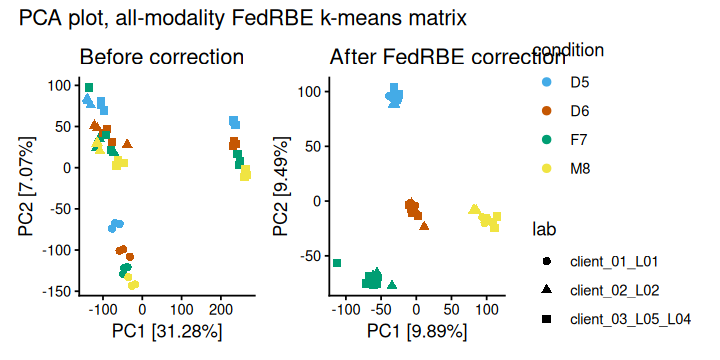

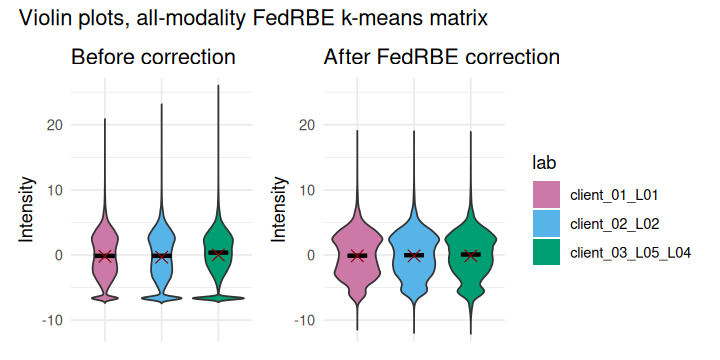

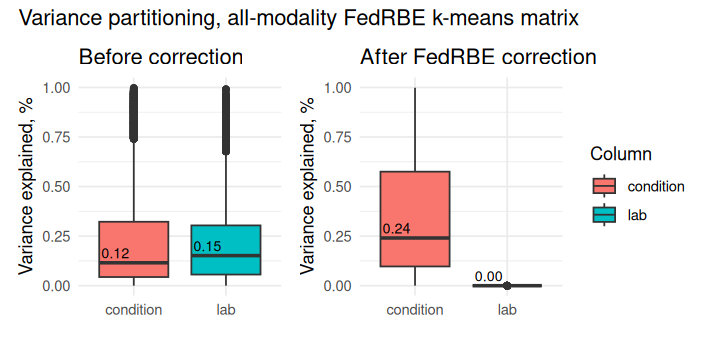

In [13]:
for (modality in modalities) {
    data <- multiomics_data[[modality]]
    if (is.null(data$fed_corrected)) {
        message("Skipping FedRBE plots for ", modality, ": FedApp_corrected_data.tsv not found")
        next
    }

    pca_plot_uncorrected <- pca_plot(data$central_uncorrected, data$metadata,
        title = "Before correction",
        quantitative_col_name = "file", col_col = "condition", shape_col = "lab",
        show_legend = FALSE, cbPalette = condition_palette)
    pca_plot_fed <- pca_plot(data$fed_corrected, data$metadata,
        title = "After FedRBE correction",
        quantitative_col_name = "file", col_col = "condition", shape_col = "lab",
        show_legend = TRUE, cbPalette = condition_palette)

    layout <- (pca_plot_uncorrected + pca_plot_fed)
    layout <- layout + plot_annotation(paste("PCA plot,", modality, "multiomics FedRBE data"))
    options(repr.plot.width = 6.5, repr.plot.height = 3.3)
    print(layout)

    y_min <- min(data$central_uncorrected, data$fed_corrected, na.rm = TRUE)
    y_max <- max(data$central_uncorrected, data$fed_corrected, na.rm = TRUE)
    y_limits <- c(y_min, y_max)

    boxplots_uncorrected <- boxplot_plot_groupped(data$central_uncorrected, data$metadata,
        title = "Before correction",
        quantitativeColumnName = "file",
        color_col = "lab", remove_xnames = TRUE, show_legend = FALSE,
        y_limits = y_limits, cbPalette = cbPalette)
    boxplots_fed <- boxplot_plot_groupped(data$fed_corrected, data$metadata,
        title = "After FedRBE correction",
        quantitativeColumnName = "file",
        color_col = "lab", remove_xnames = TRUE,
        y_limits = y_limits, cbPalette = cbPalette)

    layout <- (boxplots_uncorrected + boxplots_fed)
    layout <- layout + plot_annotation(paste("Violin plots,", modality, "multiomics FedRBE data"))
    options(repr.plot.width = 6, repr.plot.height = 3)
    print(layout)

    lmpv_plot_fed <- lmpv_plot(data$fed_corrected, data$metadata,
        title = "After FedRBE correction", form = form)
    lmpv_plot_uncorrected <- lmpv_plot(data$central_uncorrected, data$metadata,
        title = "Before correction", show_legend = FALSE, form = form)

    layout <- (lmpv_plot_uncorrected + lmpv_plot_fed)
    layout <- layout + plot_annotation(paste("Variance partitioning,", modality, "multiomics FedRBE data"))
    options(repr.plot.width = 6, repr.plot.height = 3)
    print(layout)
}

if (!is.null(combined$fed_corrected)) {
    pca_plot_uncorrected <- pca_plot(combined$central_uncorrected, combined$metadata,
        title = "Before correction",
        quantitative_col_name = "file", col_col = "condition", shape_col = "lab",
        show_legend = FALSE, cbPalette = condition_palette)
    pca_plot_fed <- pca_plot(combined$fed_corrected, combined$metadata,
        title = "After FedRBE correction",
        quantitative_col_name = "file", col_col = "condition", shape_col = "lab",
        show_legend = TRUE, cbPalette = condition_palette)

    layout <- (pca_plot_uncorrected + pca_plot_fed)
    layout <- layout + plot_annotation("PCA plot, all-modality FedRBE k-means matrix")
    options(repr.plot.width = 6.5, repr.plot.height = 3.3)
    print(layout)

    y_min <- min(combined$central_uncorrected, combined$fed_corrected, na.rm = TRUE)
    y_max <- max(combined$central_uncorrected, combined$fed_corrected, na.rm = TRUE)
    y_limits <- c(y_min, y_max)

    boxplots_uncorrected <- boxplot_plot_groupped(combined$central_uncorrected, combined$metadata,
        title = "Before correction",
        quantitativeColumnName = "file",
        color_col = "lab", remove_xnames = TRUE, show_legend = FALSE,
        y_limits = y_limits, cbPalette = cbPalette)
    boxplots_fed <- boxplot_plot_groupped(combined$fed_corrected, combined$metadata,
        title = "After FedRBE correction",
        quantitativeColumnName = "file",
        color_col = "lab", remove_xnames = TRUE,
        y_limits = y_limits, cbPalette = cbPalette)

    layout <- (boxplots_uncorrected + boxplots_fed)
    layout <- layout + plot_annotation("Violin plots, all-modality FedRBE k-means matrix")
    options(repr.plot.width = 6, repr.plot.height = 3)
    print(layout)

    lmpv_plot_fed <- lmpv_plot(combined$fed_corrected, combined$metadata,
        title = "After FedRBE correction", form = form)
    lmpv_plot_uncorrected <- lmpv_plot(combined$central_uncorrected, combined$metadata,
        title = "Before correction", show_legend = FALSE, form = form)

    layout <- (lmpv_plot_uncorrected + lmpv_plot_fed)
    layout <- layout + plot_annotation("Variance partitioning, all-modality FedRBE k-means matrix")
    options(repr.plot.width = 6, repr.plot.height = 3)
    print(layout)
}

# Session info

In [14]:
sessionInfo()

R version 4.5.3 (2026-03-11)
Platform: x86_64-conda-linux-gnu
Running under: Ubuntu 26.04 LTS

Matrix products: default
BLAS/LAPACK: /home/yuliya/repos/cosybio/fedRBE/.pixi/envs/default/lib/libopenblasp-r0.3.34.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Europe/Berlin
tzcode source: system (glibc)

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] variancePartition_1.40.2 BiocParallel_1.44.0      limma_3.66.0            
 [4] viridis_0.6.5            viridisLite_0.4.3        ggsci_5.2.0             
 [7] umap_0.2.10.0            patchwork_1.3.